# NYC building facades: predicting unsafe facade inspections
Day 2 assignment, supervised learning

**Team:** Amelia, Jerome, Kazuko, Sahil
**Course:** AI Methods I, IAAC MaAI 2026/27

This notebook trains, evaluates and saves a model that predicts whether a building's facade inspection will come out **UNSAFE**.
It loads the cleaned dataset produced by `data_cleaning_and_EDA.ipynb` (run that notebook first).

# 0. Introduction and problem definition

### Use case
In New York City, every building taller than 6 stories must have its facade inspected every 5 years (FISP, Local Law 11).
An **UNSAFE** facade can drop bricks, stone or terra cotta onto the sidewalk.

**Who uses the model, and for what?** The NYC Department of Buildings (DOB) or a facade consultant, at the **start of a new 5-year cycle,
before any inspection is done**, to rank buildings by risk and decide which facades to inspect and follow up first.

**Which mistake is more expensive?** Missing an UNSAFE facade (a false negative) can injure or kill someone on the street.
A false alarm only costs an earlier inspection. So **catching UNSAFE facades (recall) matters more than avoiding false alarms (precision)**.

**What does the user know at prediction time?** Only what is known *before* the inspection: the result of the building's previous cycle,
its borough, the cycle, and the facade materials and wall types. Everything that comes with or after the new report
(penalties, filing type, filing dates) is **leakage** and cannot be an input.

### Problem definition

| | |
|---|---|
| **Problem type** | Binary classification |
| **Target** | `IS_UNSAFE`: 1 = UNSAFE, 0 = SAFE or SWARMP (safe with a repair and maintenance program) |
| **Main metric** | **F2 score** |

**Why F2?** F-scores combine precision and recall. F1 weighs them equally; **F2 counts recall twice as much as precision**, which matches
our use case: a missed UNSAFE facade is worse than an extra inspection. We also report recall, precision, balanced accuracy and accuracy.
Accuracy alone would be misleading: only ~23% of the filings are UNSAFE, so a model that always says "not unsafe" is already ~77% accurate.

## 0.1 Libraries

Same as Day 1 (pandas, numpy, matplotlib, seaborn), plus **scikit-learn** (`sklearn`), the main machine learning library in Python.
scikit-learn is organised in **modules**; we import each tool from its module the first time we use it, so we learn where things live:

| Module | Contains |
|---|---|
| `sklearn.model_selection` | Splitting data, cross-validation, hyperparameter search |
| `sklearn.preprocessing` / `sklearn.impute` | Scalers, encoders, imputers |
| `sklearn.pipeline` / `sklearn.compose` | Pipelines and column transformers |
| `sklearn.linear_model`, `.neighbors`, `.tree`, `.ensemble` | The models |
| `sklearn.metrics` | Evaluation metrics |
| `sklearn.inspection` | Tools to interpret models |

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib   # to save and load trained models
import sklearn

print(f"scikit-learn {sklearn.__version__}, pandas {pd.__version__}, numpy {np.__version__}")

scikit-learn 1.9.1, pandas 3.1.0, numpy 2.5.4


In [2]:
# --- Folders (the notebook lives in notebook/, so the other folders are one level up) ---
DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"   # the trained model is saved here
for folder in [FIG_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

# --- Display and plot settings (same as the cleaning notebook) ---
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# The same seed everywhere: same splits, same "random" models, same results for everybody
RANDOM_STATE = 42


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

## 0.2 Load the data

We load the table saved at the end of `data_cleaning_and_EDA.ipynb` (section 1.11), so all the cleaning is already done:
duplicates and placeholder "no report" filings removed, text in one style, dates converted, typos fixed,
and the facade materials and wall types turned into 1/0 columns.
The file is not on GitHub (`.gitignore`), so if it is missing, run the cleaning notebook first.

In [3]:
clean_path = DATA_DIR / "processed" / "facades_clean.csv"

if not clean_path.exists():
    raise FileNotFoundError(
        f"{clean_path} not found. Run notebook/data_cleaning_and_EDA.ipynb first: it creates this file."
    )

df = pd.read_csv(clean_path, low_memory=False)
print(f"Facade filings: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(3)

Facade filings: 67,659 rows x 42 columns


,TR6_NO,BIN,BOROUGH,BLOCK,LOT,HOUSE_NO,STREET_NAME,FILING_TYPE,CYCLE,SEQUENCE_NO,FILING_YEAR,FILING_STATUS,IS_UNSAFE,PRIOR_STATUS,HAS_PRIOR_CYCLE,EXTERIOR_WALL_TYPES,EXTERIOR_WALL_MATERIALS,WALL_TYPE_BRICK_MASONRY,WALL_TYPE_OTHER,WALL_TYPE_MASONRY_LOAD_BEARING_WALL,WALL_TYPE_TERRA_COTTA,WALL_TYPE_MASONRY_CAVITY_WALL,WALL_TYPE_STEEL_FRAME,WALL_TYPE_CONCRETE,WALL_TYPE_CONCRETE_FRAME,MATERIAL_MASONRY,MATERIAL_OTHER,MATERIAL_TERRA_COTTA,MATERIAL_NATURAL_STONE,MATERIAL_CONCRETE,MATERIAL_STUCCO_EIFS,MATERIAL_GLASS,MATERIAL_METAL,FIELD_INSPECTION_COMPLETED_DATE,FILING_DATE,PRIOR_CYCLE_FILING_DATE,QEWI_SIGNED_DATE,DAYS_INSPECTION_TO_FILING,LATE_FILING_AMT,FAILURE_TO_FILE_AMT,FAILURE_TO_CORRECT_AMT,TOTAL_PENALTY_AMT
0,TR6-802744-8A-I1,"1,019,150.000",MANHATTAN,894.000,52,148,EAST 39 STREET,INITIAL,8.000,1.000,"2,018.000",SWARMP,0,SWARMP,1,BRICK MASONRY,MASONRY,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,2018-03-22,2018-04-09,2012-02-21,2018-09-27,18.000,"3,500.000","1,000.000",0.000,"4,500.000"
1,TR6-709724-7A-I1,"3,326,542.000",BROOKLYN,"3,576.000",1,300,DUMONT AVENUE,INITIAL,7.000,7.000,"2,012.000",SAFE,0,SAFE,1,OTHER,OTHER,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,2012-10-25,2012-12-03,2010-02-16,2012-11-30,39.000,0.000,0.000,0.000,0.000
2,TR6-611824-NA-I1,"4,436,310.000",QUEENS,"16,114.000",2,8201,HAMMELS BOULEVARD,INITIAL,6.000,4.000,"2,009.000",SAFE,0,SAFE,1,OTHER,OTHER,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,2008-03-11,2009-10-16,2003-03-25,2009-09-30,584.000,0.000,0.000,0.000,0.000


In [4]:
# The target in the cleaned data
status = df["FILING_STATUS"].value_counts()
pd.DataFrame({"filings": status, "%": status / status.sum() * 100}).round(1)

,filings,%
FILING_STATUS,,
SAFE,28080,41.500
SWARMP,24467,36.200
UNSAFE,15112,22.300


# 1. Features, leakage and split

## 1.1 Which filings? A hidden leak in `FILING_TYPE`

In [5]:
# % of each result per filing type
pd.crosstab(df["FILING_TYPE"], df["FILING_STATUS"], normalize="index").mul(100).round(1)

FILING_STATUS,SAFE,SWARMP,UNSAFE
FILING_TYPE,,,
AMENDED,74.500,25.500,0.000
INITIAL,36.800,40.000,23.200
SUBSEQUENT,28.600,10.700,60.700


The filing type gives the answer away:
- **AMENDED** filings are corrections sent after repairs: 0% UNSAFE
- **SUBSEQUENT** filings are follow-ups that only exist *because* the facade was UNSAFE: 61% UNSAFE
- **INITIAL** is the first report for a building in a cycle: 23% UNSAFE

A model would learn "SUBSEQUENT = UNSAFE", which is useless before an inspection (it's leakage).
Our use case is the first inspection of a new cycle, so we keep **only INITIAL filings**: one row per building per cycle.

In [6]:
rows_before = len(df)
df_model = df[df["FILING_TYPE"] == "INITIAL"].copy()

# A few filings have no building id (BIN, needed for the split in 1.4) or no cycle
df_model = df_model[df_model["BIN"].notna() & df_model["CYCLE"].notna()].reset_index(drop=True)

print(f"Kept {len(df_model):,} of {rows_before:,} filings ({df_model['BIN'].nunique():,} buildings)")

Kept 54,049 of 67,659 filings (15,767 buildings)


## 1.2 Target and features

**Target `y`:** `IS_UNSAFE` (1 = UNSAFE, 0 = SAFE or SWARMP). It is a yes/no class, so there is no log transform (that's only for skewed regression targets).

**Features `X`:** only what is known before the inspection.

| Feature | Type | Why we use it |
|---|---|---|
| `PRIOR_STATUS` | nominal category | strongest signal in the EDA: UNSAFE before → 40% UNSAFE again vs 14% after SAFE. Missing = first cycle in the data → `NO PRIOR CYCLE` |
| `BOROUGH` | nominal category | Brooklyn (30%) and the Bronx (26%) have more UNSAFE facades than Manhattan (20%) |
| `CYCLE` | nominal category (**stored as a number**) | cycle 9 has clearly more UNSAFE results. Each cycle is a period with its own rules and inspectors, not a quantity |
| `MATERIAL_...` (8 columns) | 1/0 | natural stone and terra cotta are more often UNSAFE, glass and metal less |
| `WALL_TYPE_...` (8 columns) | 1/0 | frame and load-bearing walls are more often UNSAFE than brick masonry |

**Columns removed as inputs:**

| Column(s) | Why |
|---|---|
| `FILING_STATUS`, `IS_UNSAFE` | the answer itself |
| `LATE_FILING_AMT`, `FAILURE_TO_FILE_AMT`, `FAILURE_TO_CORRECT_AMT`, `TOTAL_PENALTY_AMT` | **leakage**: fines are given *after* the result (failure to correct only exists for unsafe facades) |
| `FILING_TYPE`, `SEQUENCE_NO` | **leakage** (see 1.1); only INITIAL filings are left anyway |
| `FIELD_INSPECTION_COMPLETED_DATE`, `FILING_DATE`, `QEWI_SIGNED_DATE`, `FILING_YEAR`, `DAYS_INSPECTION_TO_FILING` | **not known at prediction time**: they only exist once the inspection is done |
| `PRIOR_CYCLE_FILING_DATE`, `HAS_PRIOR_CYCLE` | already covered by `PRIOR_STATUS` |
| `TR6_NO`, `BIN`, `BLOCK`, `LOT`, `HOUSE_NO`, `STREET_NAME` | identifiers and addresses: a model would memorise buildings instead of learning patterns. `BIN` is only used to split by building (1.4) |
| `EXTERIOR_WALL_TYPES`, `EXTERIOR_WALL_MATERIALS` | the original text lists; we use their 1/0 columns instead |

In [7]:
material_features = [c for c in df_model.columns if c.startswith("MATERIAL_")]
wall_features = [c for c in df_model.columns if c.startswith("WALL_TYPE_")]

nominal_features = ["PRIOR_STATUS", "BOROUGH", "CYCLE"]
binary_features = material_features + wall_features
features = nominal_features + binary_features

# Missing prior status = the building's first cycle in the data: a category of its own
df_model["PRIOR_STATUS"] = df_model["PRIOR_STATUS"].fillna("NO PRIOR CYCLE")

# CYCLE is stored as a number (6.0, 7.0...) but is a category: turn it into text ("6", "7"...)
df_model["CYCLE"] = df_model["CYCLE"].astype(int).astype(str)

X = df_model[features].copy()
X[binary_features] = X[binary_features].astype(float)   # 1.0 / 0.0, missing as NaN (filled in the pipeline)
y = df_model["IS_UNSAFE"]
groups = df_model["BIN"]                                 # building id, used for the split

print(f"X: {X.shape[0]:,} rows x {X.shape[1]} features ({len(nominal_features)} nominal, {len(binary_features)} binary)")
print(f"y: {y.sum():,} UNSAFE ({y.mean() * 100:.1f}%)")

X: 54,049 rows x 19 features (3 nominal, 16 binary)
y: 12,552 UNSAFE (23.2%)


## 1.3 Check the features

In [8]:
# Missing values per feature
missing = X.isna().mean().mul(100).round(1)
print("Features with missing values (%):")
print(missing[missing > 0].to_string())

# Categories of the nominal features
for col in nominal_features:
    print(f"\n{col}: {X[col].value_counts().to_dict()}")

Features with missing values (%):
MATERIAL_MASONRY                      3.400
MATERIAL_OTHER                        3.400
MATERIAL_TERRA_COTTA                  3.400
MATERIAL_NATURAL_STONE                3.400
MATERIAL_CONCRETE                     3.400
MATERIAL_STUCCO_EIFS                  3.400
MATERIAL_GLASS                        3.400
MATERIAL_METAL                        3.400
WALL_TYPE_BRICK_MASONRY               3.400
WALL_TYPE_OTHER                       3.400
WALL_TYPE_MASONRY_LOAD_BEARING_WALL   3.400
WALL_TYPE_TERRA_COTTA                 3.400
WALL_TYPE_MASONRY_CAVITY_WALL         3.400
WALL_TYPE_STEEL_FRAME                 3.400
WALL_TYPE_CONCRETE                    3.400
WALL_TYPE_CONCRETE_FRAME              3.400

PRIOR_STATUS: {'SAFE': 22772, 'SWARMP': 21327, 'NO PRIOR CYCLE': 5018, 'UNSAFE': 2860, 'NO REPORT FILED': 2072}

BOROUGH: {'MANHATTAN': 32431, 'BROOKLYN': 7240, 'BRONX': 7017, 'QUEENS': 6878, 'STATEN ISLAND': 483}

CYCLE: {'9': 13546, '8': 12868, '7': 12413, '6

Material and wall type are missing for 3.4% of the filings (all 16 columns at once: the report had no wall information).
We don't fill them here: the pipeline (section 2) fills them **using only the training data**, so nothing leaks from the test set.

## 1.4 Train / test split: stratified **and** by building

The usual split is `train_test_split(X, y, stratify=y)`: random rows, same share of UNSAFE in train and test.
But here **the same building appears in several cycles** (up to 5 initial filings per building).
With a random split, a building's cycle 8 could be in the training set and its cycle 9 in the test set: the model would be tested on
buildings it has already seen, and the test score would be too optimistic.

`StratifiedGroupKFold` solves both: it keeps all filings of a building together (**group** = `BIN`) and keeps the share of UNSAFE
about the same in every part (**stratified**). We split the data into 5 parts and use one of them (20%) as the test set.
The test set is then **locked until section 5**.

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

# 5 parts, all filings of a building in the same part, similar % UNSAFE in each part
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))   # the first part (20%) is the test set

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print(f"Training set: {len(X_train):,} filings, {groups_train.nunique():,} buildings")
print(f"Test set:     {len(X_test):,} filings, {groups.iloc[test_idx].nunique():,} buildings (locked away until section 5!)")
print(f"Buildings in both sets: {len(set(groups_train) & set(groups.iloc[test_idx]))}")

pd.DataFrame({
    "train (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "test (%)": y_test.value_counts(normalize=True).sort_index() * 100,
}, index=[0, 1]).rename(index={0: "not UNSAFE", 1: "UNSAFE"}).round(1)

Training set: 43,239 filings, 12,586 buildings
Test set:     10,810 filings, 3,181 buildings (locked away until section 5!)
Buildings in both sets: 0


,train (%),test (%)
not UNSAFE,76.800,76.800
UNSAFE,23.200,23.200


No building is in both sets, and the share of UNSAFE is the same in train and test.

For **cross-validation** (sections 3 and 4) we split the training set the same way into 5 folds, and save the folds as a list,
so **every model is evaluated on exactly the same folds**.

In [10]:
cv_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_folds = list(cv_splitter.split(X_train, y_train, groups_train))   # the same 5 folds for every model

for i, (fold_train, fold_valid) in enumerate(cv_folds, start=1):
    print(f"Fold {i}: {len(fold_train):,} train / {len(fold_valid):,} validation, "
          f"{y_train.iloc[fold_valid].mean() * 100:.1f}% UNSAFE in validation")

Fold 1: 34,593 train / 8,646 validation, 23.2% UNSAFE in validation
Fold 2: 34,592 train / 8,647 validation, 23.2% UNSAFE in validation
Fold 3: 34,590 train / 8,649 validation, 23.2% UNSAFE in validation
Fold 4: 34,590 train / 8,649 validation, 23.2% UNSAFE in validation
Fold 5: 34,591 train / 8,648 validation, 23.2% UNSAFE in validation


# 2. Preprocessing pipeline

All preprocessing goes inside a scikit-learn `Pipeline`, so during cross-validation it is **learned on the training folds only**
and then applied to the validation fold. Nothing leaks.

| Columns | Steps | Why |
|---|---|---|
| nominal: `PRIOR_STATUS`, `BOROUGH`, `CYCLE` | most frequent value for gaps → **one-hot encoding** | none of them has a natural order. `PRIOR_STATUS` *looks* ordered (SAFE < SWARMP < UNSAFE) but `NO PRIOR CYCLE` and `NO REPORT FILED` don't fit on that scale, so an ordinal encoder would invent an order. `CYCLE` is a **category stored as a number**: as a number, a model would assume cycle 9 is "more" than cycle 8 in a straight line |
| binary: 8 materials + 8 wall types (1/0) | most frequent value for gaps | they are already numbers 0/1; the most frequent value is 0 for all but masonry and brick masonry |

**Scaling:** after encoding, *every* column is 0 or 1, so all inputs are already on the same scale. Scaling (`StandardScaler`) is
not needed here, not even for the linear model. (It would matter for numeric columns like areas or years, which we don't have.)

`handle_unknown="ignore"` in the one-hot encoder: a category never seen in training (e.g. a future cycle 11) becomes all zeros
instead of crashing the model.

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder


def make_pipeline_for(model):
    # Build preprocessing + model as one Pipeline
    nominal_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    binary_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
    ])
    preprocessor = ColumnTransformer([
        ("nom", nominal_pipeline, nominal_features),   # (name, transformer, columns)
        ("bin", binary_pipeline, binary_features),
    ])
    return Pipeline([
        ("preprocess", preprocessor),
        ("model", model),
    ])


# Example with a placeholder model, to look at the result of the preprocessing
from sklearn.dummy import DummyClassifier

example_pipeline = make_pipeline_for(DummyClassifier()).fit(X_train, y_train)
feature_names = example_pipeline.named_steps["preprocess"].get_feature_names_out()
print(f"{X_train.shape[1]} original columns -> {len(feature_names)} columns after preprocessing")
example_pipeline

19 original columns -> 31 columns after preprocessing


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['PRIOR_STATUS','BOROUGH','CYCLE',...,'WALL_TYPE_STEEL_FRAME', 'WALL_TYPE_CONCRETE','WALL_TYPE_CONCRETE_FRAME']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('nom', ...), ('bin', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specif

In [12]:
# What the model actually sees: the first 3 training rows after preprocessing
preprocessed = pd.DataFrame(
    example_pipeline.named_steps["preprocess"].transform(X_train.head(3)),
    columns=feature_names,
)
preprocessed.iloc[:, :14]

,nom__PRIOR_STATUS_NO PRIOR CYCLE,nom__PRIOR_STATUS_NO REPORT FILED,nom__PRIOR_STATUS_SAFE,nom__PRIOR_STATUS_SWARMP,nom__PRIOR_STATUS_UNSAFE,nom__BOROUGH_BRONX,nom__BOROUGH_BROOKLYN,nom__BOROUGH_MANHATTAN,nom__BOROUGH_QUEENS,nom__BOROUGH_STATEN ISLAND,nom__CYCLE_10,nom__CYCLE_6,nom__CYCLE_7,nom__CYCLE_8
0,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000
1,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000
2,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000


# 3. Model comparison

We compare **3 baselines and 4 model families** with the same 5 folds and the same metrics:

| Model | Family | Settings |
|---|---|---|
| Baseline (most frequent) | dummy | always predicts "not UNSAFE" |
| Baseline (random, stratified) | dummy | guesses UNSAFE ~23% of the time, at random |
| Baseline (always UNSAFE) | dummy | always predicts UNSAFE = "inspect every building". Important for F2: it gets recall = 1 for free |
| Logistic regression | **linear** | `class_weight="balanced"` |
| Decision tree | tree | `max_depth=6`, `class_weight="balanced"` |
| Random forest | **tree ensemble** (bagging) | 200 trees, `min_samples_leaf=5`, `class_weight="balanced"` |
| Gradient boosting | **tree ensemble** (boosting) | `HistGradientBoostingClassifier`, `class_weight="balanced"` |

**`class_weight="balanced"`:** UNSAFE is only 23% of the data. Without it, models learn that "not UNSAFE" is almost always right
and rarely predict UNSAFE, which gives a low recall. Balanced weights make each UNSAFE filing count ~3x more during training,
which pushes the models to catch more of them: exactly what F2 rewards.

In [13]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, fbeta_score, precision_score

# F2 is not a built-in scorer name, so we make one: fbeta_score with beta=2 (recall counts 2x)
f2_scorer = make_scorer(fbeta_score, beta=2, zero_division=0)

classification_scoring = {
    "F2": f2_scorer,
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "balanced accuracy": "balanced_accuracy",
    "accuracy": "accuracy",
}


def compare_models(pipelines, X, y, cv, scoring):
    # Cross-validate every pipeline and return one row of results per model (same as in class)
    rows = []
    for name, pipeline in pipelines.items():
        start = time.time()
        res = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, n_jobs=-1)  # n_jobs=-1: use all CPU cores
        row = {"model": name}
        for metric in scoring:
            scores = res[f"test_{metric}"]
            row[f"{metric} mean"] = scores.mean()
            row[f"{metric} std"] = scores.std()
        row["fit time (s)"] = res["fit_time"].mean()
        rows.append(row)
        print(f"{name:<32} done in {time.time() - start:5.1f} s")
    return pd.DataFrame(rows).set_index("model")

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

classification_pipelines = {
    "Baseline (most frequent)": make_pipeline_for(DummyClassifier(strategy="most_frequent")),
    "Baseline (random, stratified)": make_pipeline_for(DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)),
    "Baseline (always UNSAFE)": make_pipeline_for(DummyClassifier(strategy="constant", constant=1)),
    "Logistic regression": make_pipeline_for(
        LogisticRegression(class_weight="balanced", max_iter=2000)),
    "Decision tree": make_pipeline_for(
        DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE)),
    "Random forest": make_pipeline_for(
        RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                               random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient boosting": make_pipeline_for(
        HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
}

classification_results = compare_models(classification_pipelines, X_train, y_train, cv_folds, classification_scoring)

Baseline (most frequent)         done in   1.2 s
Baseline (random, stratified)    done in   1.0 s
Baseline (always UNSAFE)         done in   1.0 s
Logistic regression              done in   0.9 s
Decision tree                    done in   0.2 s
Random forest                    done in   1.3 s
Gradient boosting                done in   0.8 s


In [15]:
# Results table: mean ± standard deviation over the 5 folds
results_table = pd.DataFrame({
    metric: classification_results[f"{metric} mean"].map("{:.3f}".format)
    + " ± " + classification_results[f"{metric} std"].map("{:.3f}".format)
    for metric in classification_scoring
})
results_table["fit time (s)"] = classification_results["fit time (s)"].round(1)
results_table

,F2,recall,precision,balanced accuracy,accuracy,fit time (s)
model,,,,,,
Baseline (most frequent),0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.768 ± 0.000,0.100
"Baseline (random, stratified)",0.226 ± 0.004,0.225 ± 0.004,0.230 ± 0.004,0.498 ± 0.002,0.645 ± 0.002,0.100
Baseline (always UNSAFE),0.602 ± 0.000,1.000 ± 0.000,0.232 ± 0.000,0.500 ± 0.000,0.232 ± 0.000,0.100
Logistic regression,0.525 ± 0.012,0.566 ± 0.015,0.406 ± 0.007,0.658 ± 0.007,0.707 ± 0.005,0.100
Decision tree,0.551 ± 0.009,0.605 ± 0.014,0.405 ± 0.007,0.668 ± 0.004,0.702 ± 0.007,0.100
Random forest,0.553 ± 0.007,0.580 ± 0.011,0.465 ± 0.009,0.689 ± 0.003,0.747 ± 0.006,0.900
Gradient boosting,0.553 ± 0.008,0.587 ± 0.015,0.451 ± 0.009,0.685 ± 0.003,0.738 ± 0.007,0.600


Figure saved to ..\figures\10_model_comparison.png


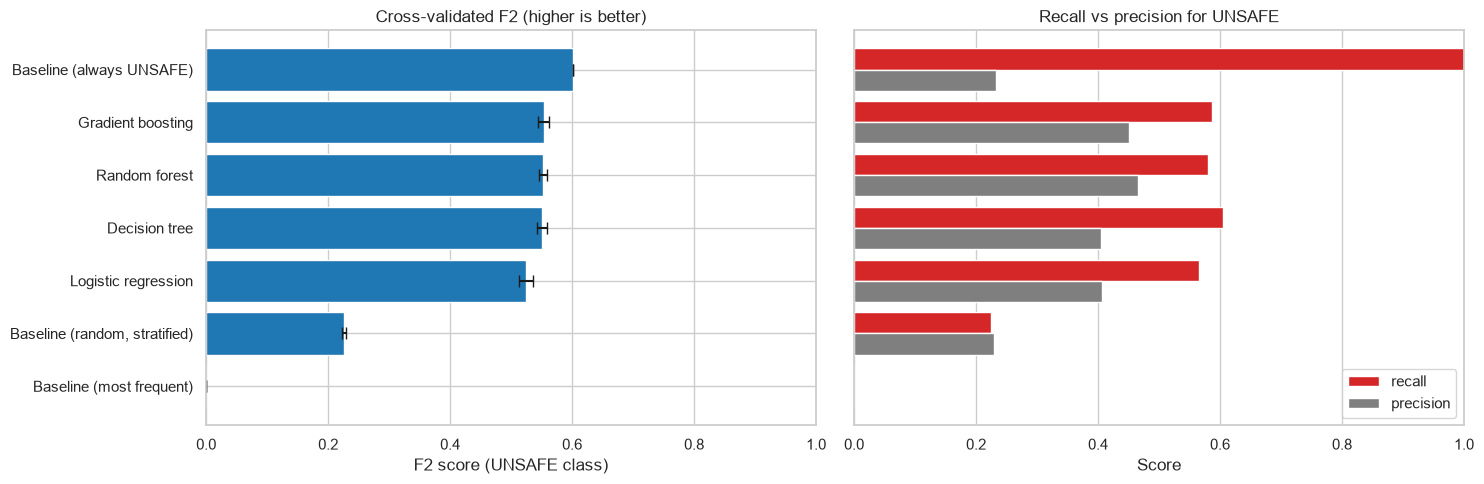

In [16]:
plot_data = classification_results.sort_values("F2 mean")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# xerr = error bars of +/- one standard deviation across the 5 folds
axes[0].barh(plot_data.index, plot_data["F2 mean"], xerr=plot_data["F2 std"], color="tab:blue", capsize=4)
axes[0].set_xlim(0, 1)
axes[0].set_title("Cross-validated F2 (higher is better)")
axes[0].set_xlabel("F2 score (UNSAFE class)")

# Recall vs precision: what each model trades
axes[1].barh(plot_data.index, plot_data["recall mean"], height=0.4, align="edge", color="tab:red", label="recall")
axes[1].barh(plot_data.index, plot_data["precision mean"], height=-0.4, align="edge", color="tab:grey", label="precision")
axes[1].set_xlim(0, 1)
axes[1].set_title("Recall vs precision for UNSAFE")
axes[1].set_xlabel("Score")
axes[1].set_yticks([])
axes[1].legend(loc="lower right")

plt.tight_layout()
save_fig("10_model_comparison")
plt.show()

**Reading the results:**
- **Accuracy is a trap here:** the "most frequent" baseline is 77% accurate and finds zero UNSAFE facades.
- **F2 has its own trap:** "always UNSAFE" (inspect every building) scores **0.602**, higher than every real model at the default
  threshold (0.525-0.553). F2 counts recall so much that flagging everything looks good. This is not a reason to inspect everything:
  it means **the 0.5 threshold is wrong for our goal**, which we fix in 4.3.
- **Which differences are real?** Decision tree, random forest and gradient boosting are within 0.002 of each other (0.551-0.553),
  much less than one standard deviation (~0.008): **a tie, the differences are noise**. Logistic regression is ~0.03 lower,
  about 3 standard deviations: that gap is real. The linear model can't combine features (e.g. "terra cotta *and* previously UNSAFE").
- **Our choice for tuning: random forest.** Same F2 as the other tree models, but the best precision (0.465) and balanced accuracy (0.689),
  so it raises the fewest false alarms for the same recall. It trains in ~1 s per fold.

# 4. Diagnosis and tuning

We tune the **random forest**: it ties for the best F2 and has the best precision and balanced accuracy (section 3).

## 4.1 Validation curve: how deep should the trees be?
`max_depth` controls how complex each tree can get. Too shallow: the model **underfits** (bad on train and validation).
Too deep: it **overfits** (great on train, worse on validation, the gap grows).

Figure saved to ..\figures\11_validation_curve.png


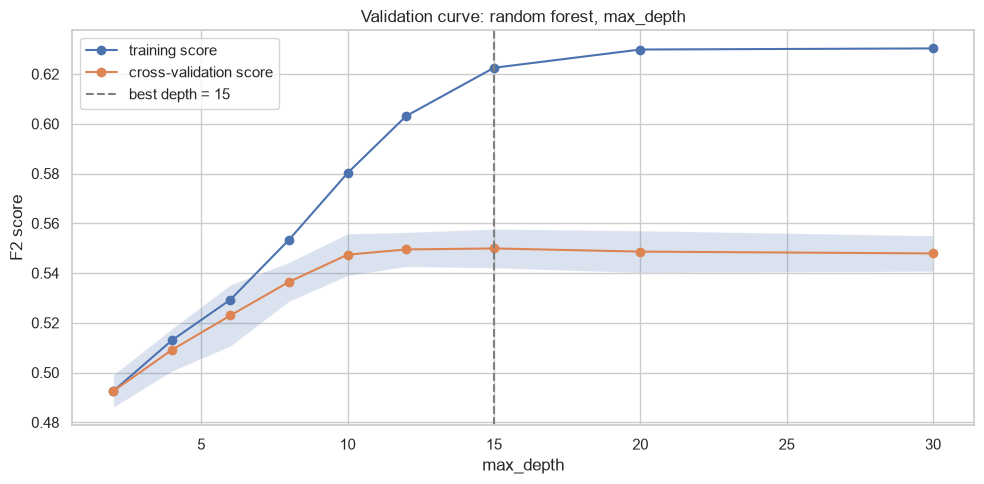

,train F2,CV F2,CV std
max_depth,,,
2,0.493,0.493,0.007
4,0.513,0.509,0.009
6,0.529,0.523,0.012
8,0.553,0.536,0.008
10,0.580,0.547,0.008
12,0.603,0.549,0.007
15,0.623,0.550,0.008
20,0.630,0.549,0.008
30,0.630,0.548,0.007


In [17]:
from sklearn.model_selection import validation_curve

depths = [2, 4, 6, 8, 10, 12, 15, 20, 30]
train_scores, cv_scores = validation_curve(
    make_pipeline_for(RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                             random_state=RANDOM_STATE, n_jobs=-1)),
    X_train, y_train,
    param_name="model__max_depth",   # step name + "__" + parameter name
    param_range=depths,
    cv=cv_folds, scoring=f2_scorer, n_jobs=-1,
)

best_depth = depths[cv_scores.mean(axis=1).argmax()]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depths, train_scores.mean(axis=1), marker="o", label="training score")
ax.plot(depths, cv_scores.mean(axis=1), marker="o", label="cross-validation score")
ax.fill_between(depths, cv_scores.mean(axis=1) - cv_scores.std(axis=1),
                cv_scores.mean(axis=1) + cv_scores.std(axis=1), alpha=0.2)
ax.axvline(best_depth, color="grey", linestyle="--", label=f"best depth = {best_depth}")
ax.set_title("Validation curve: random forest, max_depth")
ax.set_xlabel("max_depth")
ax.set_ylabel("F2 score")
ax.legend()
plt.tight_layout()
save_fig("11_validation_curve")
plt.show()

pd.DataFrame({"train F2": train_scores.mean(axis=1), "CV F2": cv_scores.mean(axis=1),
              "CV std": cv_scores.std(axis=1)}, index=pd.Index(depths, name="max_depth")).round(3)

- **Depth 2-6: underfitting.** Training and CV scores are low and almost equal: the trees are too simple to use the information.
- **Depth 10 and more: mild overfitting.** The training score keeps going up (0.58 → 0.63) but the CV score stays flat at ~0.55: the gap grows,
  so the extra depth learns noise of the training buildings, not patterns that generalise.
- The CV score is flat from depth 12 to 30 (0.548-0.550, differences far below one std). We keep depth **12**: as good as deeper trees,
  but simpler and faster.

## 4.2 `GridSearchCV`: tuning several settings at once
We try combinations of tree depth, minimum leaf size and number of features per split, with the same 5 folds and F2.

In [18]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__max_depth": [6, 8, 10, 12],
    "model__min_samples_leaf": [1, 5, 20],
    "model__max_features": ["sqrt", 0.5],
}

start = time.time()
grid_search = GridSearchCV(
    make_pipeline_for(RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                             random_state=RANDOM_STATE, n_jobs=-1)),
    param_grid,
    cv=cv_folds,
    scoring=f2_scorer,
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)
print(f"Tried {len(grid_search.cv_results_['params'])} combinations x 5 folds in {time.time() - start:.0f} s")
print("Best settings:", grid_search.best_params_)
print(f"Best cross-validated F2: {grid_search.best_score_:.3f} "
      f"(default random forest: {classification_results.loc['Random forest', 'F2 mean']:.3f})")

Tried 24 combinations x 5 folds in 28 s
Best settings: {'model__max_depth': 12, 'model__max_features': 0.5, 'model__min_samples_leaf': 5}
Best cross-validated F2: 0.555 (default random forest: 0.553)


In [19]:
# The 5 best combinations
grid_table = pd.DataFrame(grid_search.cv_results_["params"])
grid_table["F2 mean"] = grid_search.cv_results_["mean_test_score"]
grid_table["F2 std"] = grid_search.cv_results_["std_test_score"]
grid_table.columns = grid_table.columns.str.replace("model__", "")
grid_table.sort_values("F2 mean", ascending=False).head(5).round(3)

,max_depth,max_features,min_samples_leaf,F2 mean,F2 std
22,12,0.500,5,0.555,0.008
21,12,0.500,1,0.553,0.008
19,12,sqrt,5,0.551,0.007
23,12,0.500,20,0.551,0.010
20,12,sqrt,20,0.550,0.009


The best combination (depth 12, 50% of the features per split, at least 5 filings per leaf) reaches **0.555**,
vs **0.553** for the default random forest: a gain of 0.002, **far below one standard deviation (0.008)**.
**Tuning the hyperparameters is not worth much here**: the limit is the information in the 19 inputs, not the model settings.
We keep the tuned settings anyway since they cost nothing, but we don't claim they improve the model.

## 4.3 Tuning the decision threshold
A classifier gives a **probability** of UNSAFE and says "UNSAFE" when it is above **0.5** by default.
But 0.5 is not special: for our use case, a **lower threshold** catches more UNSAFE facades (higher recall) at the cost of more
false alarms (lower precision). `TunedThresholdClassifierCV` tries many thresholds with the same 5 folds and keeps the one with the
best F2. The threshold is a choice like any other setting, so it is chosen with cross-validation, never on the test set.

Best threshold: 0.30 (default 0.50)
Cross-validated F2 at this threshold: 0.626 (at 0.50: 0.555)
Figure saved to ..\figures\12_decision_threshold.png


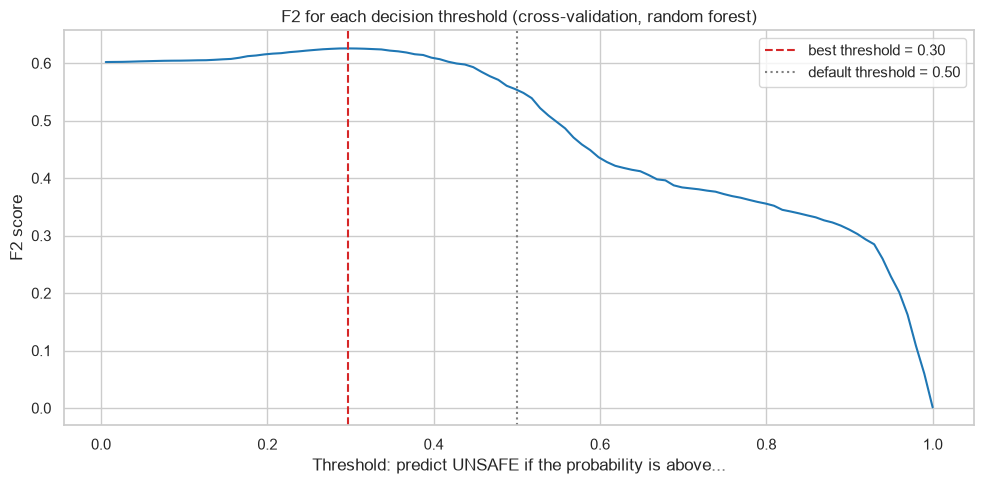

In [20]:
from sklearn.model_selection import TunedThresholdClassifierCV

tuned_model = TunedThresholdClassifierCV(
    grid_search.best_estimator_,   # the tuned random forest pipeline
    scoring=f2_scorer,
    cv=cv_folds,
    store_cv_results=True,
    n_jobs=-1,
)
tuned_model.fit(X_train, y_train)

print(f"Best threshold: {tuned_model.best_threshold_:.2f} (default 0.50)")
print(f"Cross-validated F2 at this threshold: {tuned_model.best_score_:.3f} "
      f"(at 0.50: {grid_search.best_score_:.3f})")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(tuned_model.cv_results_["thresholds"], tuned_model.cv_results_["scores"], color="tab:blue")
ax.axvline(tuned_model.best_threshold_, color="tab:red", linestyle="--",
           label=f"best threshold = {tuned_model.best_threshold_:.2f}")
ax.axvline(0.5, color="grey", linestyle=":", label="default threshold = 0.50")
ax.set_title("F2 for each decision threshold (cross-validation, random forest)")
ax.set_xlabel("Threshold: predict UNSAFE if the probability is above...")
ax.set_ylabel("F2 score")
ax.legend()
plt.tight_layout()
save_fig("12_decision_threshold")
plt.show()

In [21]:
# What the threshold changes: recall and precision with the same 5 folds
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score, precision_score

proba_oof = cross_val_predict(grid_search.best_estimator_, X_train, y_train, cv=cv_folds,
                              method="predict_proba", n_jobs=-1)[:, 1]   # out-of-fold probability of UNSAFE

rows = []
for name, threshold in [("default (0.50)", 0.5), (f"tuned ({tuned_model.best_threshold_:.2f})", tuned_model.best_threshold_)]:
    pred = (proba_oof >= threshold).astype(int)
    rows.append({
        "threshold": name,
        "F2": fbeta_score(y_train, pred, beta=2),
        "recall": recall_score(y_train, pred),
        "precision": precision_score(y_train, pred),
        "% of filings flagged UNSAFE": pred.mean() * 100,
    })
pd.DataFrame(rows).set_index("threshold").round(3)

,F2,recall,precision,% of filings flagged UNSAFE
threshold,,,,
default (0.50),0.555,0.585,0.460,29.510
tuned (0.30),0.626,0.916,0.276,77.208


The threshold matters much more than the hyperparameters: lowering it from 0.50 to **0.30** raises the CV F2 from 0.555 to **0.626**
and recall from 0.59 to **0.92**. But look at the price: precision drops to 0.28, and **the model now flags 77% of the filings as UNSAFE**.

That is close to the "always UNSAFE" baseline (F2 0.602, 100% flagged). With a weak signal, F2's preference for recall pushes the
yes/no decision towards "inspect almost everything". **The yes/no output alone is therefore not very useful**; the value of the model
is in its **ranking** of buildings by probability, which we evaluate in section 5. We keep the 0.30 threshold as the model's yes/no
decision because it is the best for our chosen metric, and we are honest about what it means.

# 5. Final evaluation on the test set (once!)

All choices are made: random forest with the settings from 4.2 and the threshold from 4.3.
`TunedThresholdClassifierCV` already **retrained the chosen pipeline on the full training set** at the end of `fit`.
Now, and only now, we use the test set: 10,810 filings from 3,181 buildings the model has never seen.

In [22]:
from sklearn.metrics import classification_report, balanced_accuracy_score, accuracy_score

final_model = tuned_model
y_pred_test = final_model.predict(X_test)

test_scores = pd.Series({
    "F2": fbeta_score(y_test, y_pred_test, beta=2),
    "recall": recall_score(y_test, y_pred_test),
    "precision": precision_score(y_test, y_pred_test),
    "balanced accuracy": balanced_accuracy_score(y_test, y_pred_test),
    "accuracy": accuracy_score(y_test, y_pred_test),
})

# Cross-validation scores of the same pipeline at the same threshold, for comparison
from sklearn.model_selection import FixedThresholdClassifier

final_at_threshold = FixedThresholdClassifier(grid_search.best_estimator_, threshold=final_model.best_threshold_)
cv_final = cross_validate(final_at_threshold, X_train, y_train, cv=cv_folds, scoring=classification_scoring, n_jobs=-1)
comparison = pd.DataFrame({
    "test set": test_scores,
    "cross-validation (mean)": [cv_final[f"test_{m}"].mean() for m in test_scores.index],
    "cross-validation (std)": [cv_final[f"test_{m}"].std() for m in test_scores.index],
})
comparison.round(3)

,test set,cross-validation (mean),cross-validation (std)
F2,0.632,0.626,0.002
recall,0.932,0.916,0.005
precision,0.277,0.276,0.002
balanced accuracy,0.597,0.594,0.003
accuracy,0.418,0.421,0.006


In [23]:
print(classification_report(y_test, y_pred_test, target_names=["not UNSAFE", "UNSAFE"], digits=3))

              precision    recall  f1-score   support

  not UNSAFE      0.927     0.263     0.410      8299
      UNSAFE      0.277     0.932     0.427      2511

    accuracy                          0.418     10810
   macro avg      0.602     0.597     0.418     10810
weighted avg      0.776     0.418     0.414     10810



Figure saved to ..\figures\13_confusion_matrix.png


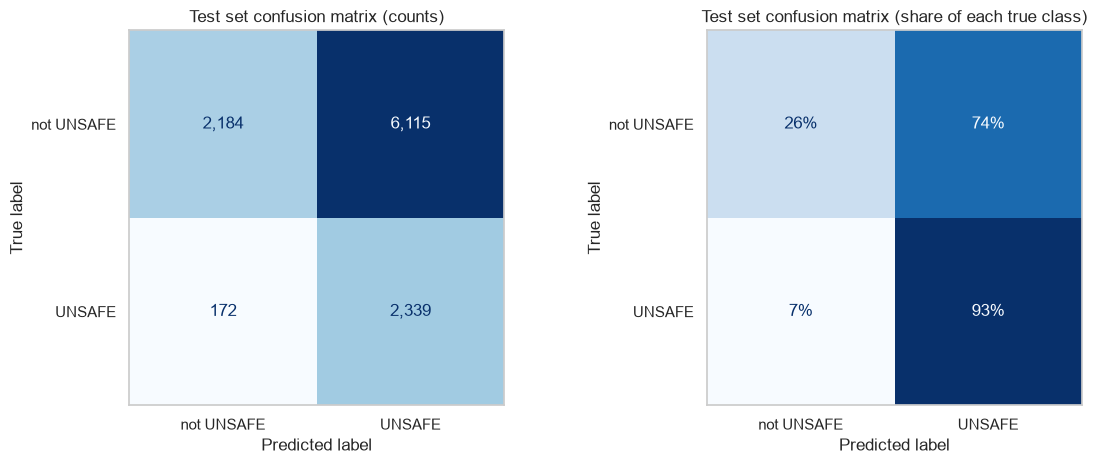

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, normalize, title in [(axes[0], None, "counts"), (axes[1], "true", "share of each true class")]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred_test, display_labels=["not UNSAFE", "UNSAFE"], normalize=normalize,
        values_format=",.0f" if normalize is None else ".0%", cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"Test set confusion matrix ({title})")
    ax.grid(False)
plt.tight_layout()
save_fig("13_confusion_matrix")
plt.show()

- **The test score matches cross-validation:** F2 0.632 on the test set vs 0.626 ± 0.002 in CV (recall 0.93 vs 0.92). No sign that we
  overfitted our choices to the validation folds, and the model works on buildings it has never seen.
- **What the confusion matrix shows:** the model catches **93% of the UNSAFE facades** (it misses about 170 of 2,511), which is what we asked for.
  But it also flags **74% of the facades that were fine** (about 6,100 false alarms). Only 28% of the flagged buildings are really UNSAFE.
- **Accuracy is 42%**, worse than always saying "not UNSAFE" (77%). That is expected with this threshold, and it's why accuracy is
  not our metric.

### The model as a ranking: which buildings to inspect first?
The yes/no prediction depends on the threshold. But the model also gives each building a **probability of UNSAFE**, which can be used to
**rank** buildings from most to least risky. If DOB can only inspect part of the buildings first, how many UNSAFE facades would it find?

- **Average precision** (area under the precision-recall curve) summarises the whole ranking in one number: 1 = perfect,
  and a random ranking scores the share of UNSAFE (~0.23).
- **Recall in the top X%**: the share of all UNSAFE facades found by inspecting the X% riskiest buildings first. Random order finds X%.

In [25]:
from sklearn.metrics import average_precision_score, roc_auc_score

proba_test = final_model.estimator_.predict_proba(X_test)[:, 1]   # probability of UNSAFE from the random forest

print(f"Average precision: {average_precision_score(y_test, proba_test):.3f}   (random ranking: {y_test.mean():.3f})")
print(f"ROC AUC:           {roc_auc_score(y_test, proba_test):.3f}   (random ranking: 0.500)")

rows = []
for share in [0.05, 0.10, 0.20, 0.30, 0.50]:
    top = proba_test >= np.quantile(proba_test, 1 - share)        # the riskiest X% of test filings
    rows.append({
        "inspect first": f"top {share:.0%}",
        "UNSAFE found (recall)": y_test[top].sum() / y_test.sum(),
        "random order would find": share,
        "times better than random": (y_test[top].sum() / y_test.sum()) / share,
        "% UNSAFE among inspected (precision)": y_test[top].mean(),
    })
ranking_table = pd.DataFrame(rows).set_index("inspect first")
ranking_table.round(2)

Average precision: 0.607   (random ranking: 0.232)
ROC AUC:           0.768   (random ranking: 0.500)


,UNSAFE found (recall),random order would find,times better than random,% UNSAFE among inspected (precision)
inspect first,,,,
top 5%,0.210,0.050,4.180,0.920
top 10%,0.350,0.100,3.480,0.780
top 20%,0.490,0.200,2.440,0.570
top 30%,0.600,0.300,1.990,0.460
top 50%,0.780,0.500,1.550,0.360


Figure saved to ..\figures\15_inspection_ranking.png


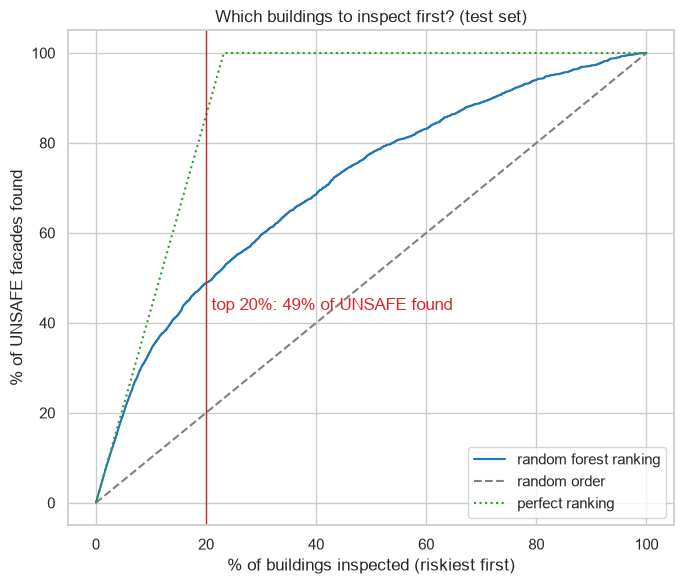

In [26]:
# Cumulative gain curve: % of UNSAFE facades found vs % of buildings inspected, in the model's order
order = np.argsort(-proba_test)
found = np.cumsum(y_test.values[order]) / y_test.sum()
inspected = np.arange(1, len(order) + 1) / len(order)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(inspected * 100, found * 100, color="tab:blue", label="random forest ranking")
ax.plot([0, 100], [0, 100], color="grey", linestyle="--", label="random order")
ax.plot([0, y_test.mean() * 100, 100], [0, 100, 100], color="tab:green", linestyle=":", label="perfect ranking")
ax.axvline(20, color="tab:red", linewidth=1)
ax.annotate(f"top 20%: {ranking_table.loc['top 20%', 'UNSAFE found (recall)']:.0%} of UNSAFE found",
            xy=(21, ranking_table.loc["top 20%", "UNSAFE found (recall)"] * 100 - 6), color="tab:red")
ax.set_title("Which buildings to inspect first? (test set)")
ax.set_xlabel("% of buildings inspected (riskiest first)")
ax.set_ylabel("% of UNSAFE facades found")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("15_inspection_ranking")
plt.show()

**This is where the model is useful.** Ranking the test buildings by their probability:
- inspecting the riskiest **10%** first finds **35%** of all UNSAFE facades (3.5x better than random), and 78% of those inspections are UNSAFE
- the riskiest **20%** finds **49%** (2.4x better than random)
- the riskiest **5%** finds 21%, and 92% of them are UNSAFE

**Average precision is 0.61** vs 0.23 for a random order (ROC AUC 0.77). So for our use case, DOB should use the model's
**probability to decide the order of inspections**, not the yes/no answer at one threshold.

### Where does the model fail?
Recall and precision per group of the test set: which UNSAFE facades does it miss, and where does it raise the most false alarms?

In [27]:
test_results = X_test[["PRIOR_STATUS", "BOROUGH", "CYCLE"]].copy()
test_results["actual"] = y_test.values
test_results["predicted"] = y_pred_test


def scores_by(column):
    rows = []
    for value, group in test_results.groupby(column):
        rows.append({
            column: value,
            "test filings": len(group),
            "% UNSAFE (actual)": group["actual"].mean() * 100,
            "% flagged (predicted)": group["predicted"].mean() * 100,
            "recall": recall_score(group["actual"], group["predicted"], zero_division=0),
            "precision": precision_score(group["actual"], group["predicted"], zero_division=0),
        })
    return pd.DataFrame(rows).set_index(column).round(2)


for column in ["PRIOR_STATUS", "BOROUGH", "CYCLE"]:
    display(scores_by(column))

,test filings,% UNSAFE (actual),% flagged (predicted),recall,precision
PRIOR_STATUS,,,,,
NO PRIOR CYCLE,1057,44.470,81.550,0.970,0.530
NO REPORT FILED,421,19.000,50.830,0.710,0.270
SAFE,4519,14.540,61.250,0.810,0.190
SWARMP,4258,21.210,95.230,0.990,0.220
UNSAFE,555,72.250,100.000,1.000,0.720


,test filings,% UNSAFE (actual),% flagged (predicted),recall,precision
BOROUGH,,,,,
BRONX,1405,27.970,79.860,0.940,0.330
BROOKLYN,1323,33.640,79.440,0.960,0.410
MANHATTAN,6574,20.660,79.450,0.930,0.240
QUEENS,1384,20.300,68.710,0.890,0.260
STATEN ISLAND,124,27.420,86.290,0.940,0.300


,test filings,% UNSAFE (actual),% flagged (predicted),recall,precision
CYCLE,,,,,
10,554,24.370,67.330,0.900,0.320
6,2454,22.290,69.070,0.910,0.290
7,2460,21.260,63.500,0.870,0.290
8,2597,23.800,91.410,0.970,0.250
9,2745,25.060,89.250,0.970,0.270


**Where the model fails:**
- **Previously SAFE buildings:** the lowest precision (0.19) and a lower recall (0.81). When a SAFE facade becomes UNSAFE, the model has
  little to go on: the main signal (previous result) points the wrong way. These are exactly the "surprises" an inspection is for.
- **Previous cycle without a report** (`NO REPORT FILED`): the lowest recall (0.71), but only 421 test filings, so less certain.
- **Previously UNSAFE or SWARMP:** the model flags almost all of them (100% and 95%). For UNSAFE that's right (72% are UNSAFE again),
  for SWARMP it causes many false alarms (only 21% are UNSAFE).
- **Cycles 8 and 9:** about 90% of the filings are flagged, vs 64-69% in cycles 6, 7 and 10. The model learned that these cycles have more
  UNSAFE results (EDA Q4) and pushes everything up.
- **Boroughs:** recall is similar everywhere (0.89-0.96); precision is lowest in Manhattan (0.24), where the share of UNSAFE is lowest.

# 6. Interpretation: which features matter?

## 6.1 Permutation importance (final model, test set)
We shuffle one input column at a time and measure how much F2 drops. A big drop = the model relies on that column.
It works for any model, and measures importance for the *original* columns (not the one-hot columns).

Computed in 4 s
Figure saved to ..\figures\14_feature_importance.png


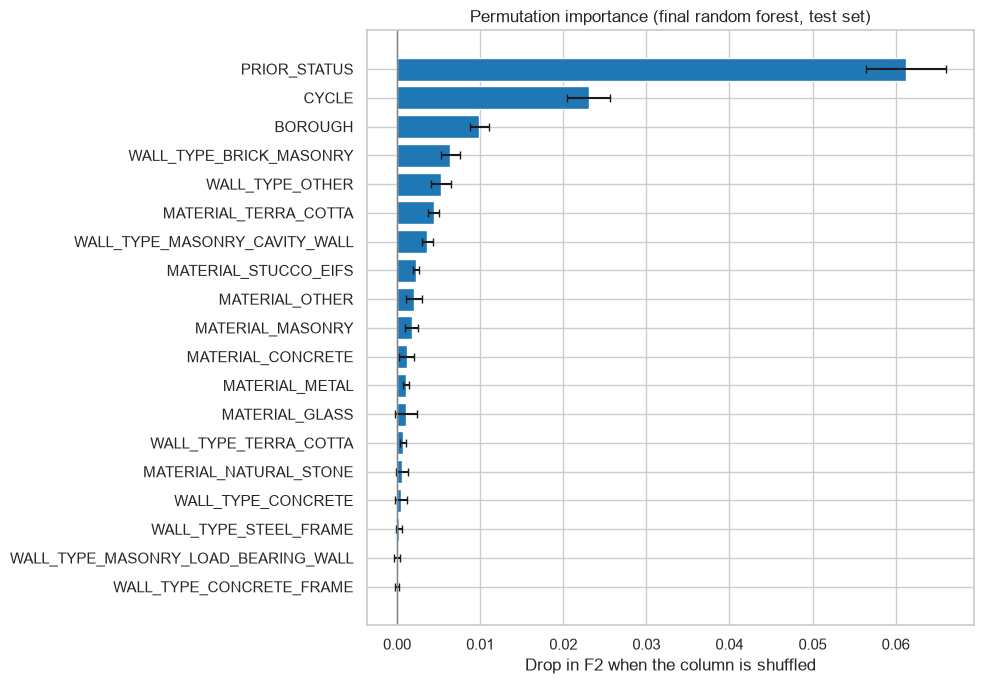

In [28]:
from sklearn.inspection import permutation_importance

start = time.time()
importance = permutation_importance(
    final_model, X_test, y_test,
    scoring=f2_scorer, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
)
print(f"Computed in {time.time() - start:.0f} s")

importance_table = pd.DataFrame({
    "mean": importance.importances_mean,
    "std": importance.importances_std,
}, index=X_test.columns).sort_values("mean")

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(importance_table.index, importance_table["mean"], xerr=importance_table["std"], color="tab:blue", capsize=3)
ax.axvline(0, color="grey", linewidth=1)
ax.set_title("Permutation importance (final random forest, test set)")
ax.set_xlabel("Drop in F2 when the column is shuffled")
plt.tight_layout()
save_fig("14_feature_importance")
plt.show()

## 6.2 Coefficients of the logistic regression
The linear model is easier to read: each one-hot column gets a coefficient. **Positive = more likely UNSAFE, negative = less likely.**
`exp(coefficient)` is the **odds ratio**: how many times the odds of UNSAFE are multiplied when that column is 1.
(Refit on the training set; for interpretation only, it is not our final model.)

In [29]:
logistic_pipeline = make_pipeline_for(LogisticRegression(class_weight="balanced", max_iter=2000)).fit(X_train, y_train)
coefficients = pd.Series(
    logistic_pipeline.named_steps["model"].coef_[0],
    index=logistic_pipeline.named_steps["preprocess"].get_feature_names_out(),
)
coefficients.index = coefficients.index.str.replace("nom__", "").str.replace("bin__", "")

coefficient_table = pd.DataFrame({"coefficient": coefficients, "odds ratio": np.exp(coefficients)})
coefficient_table.sort_values("coefficient", ascending=False).round(2)

,coefficient,odds ratio
PRIOR_STATUS_UNSAFE,1.630,5.090
PRIOR_STATUS_NO PRIOR CYCLE,0.780,2.190
CYCLE_8,0.440,1.550
MATERIAL_TERRA_COTTA,0.430,1.540
BOROUGH_BROOKLYN,0.340,1.400
WALL_TYPE_OTHER,0.320,1.380
MATERIAL_CONCRETE,0.300,1.350
MATERIAL_MASONRY,0.290,1.340
MATERIAL_NATURAL_STONE,0.230,1.260
CYCLE_6,0.180,1.200


**What the model relies on, read as designers / engineers:**
- **The previous inspection result is by far the most important input** (F2 drops 0.061 when it is shuffled, 3x more than anything else).
  In the logistic regression, a previously UNSAFE facade has **5.1x** the odds of being UNSAFE again; a previously SAFE one 0.36x.
  This makes sense: facade problems (cracked terra cotta, corroded anchors, loose brick) build up slowly and are often not fully fixed
  within 5 years. Buildings with **no previous cycle** in the data also have higher odds (2.2x): many are first inspections of older stock.
- **Cycle (0.023) and borough (0.010)** come next. Cycle reflects changes in rules and inspection practice over time, not the facade itself.
  Borough is a proxy for things we don't have (building age, maintenance budgets): it is a correlation, not a cause.
- **Materials and wall types matter little** (≤ 0.006 each). The directions agree with the EDA and with engineering sense:
  terra cotta (1.5x) is more often UNSAFE (it cracks and its steel anchors rust), while glass curtain walls (0.51x) and brick masonry walls
  (0.52x) are less often UNSAFE.
- Overall the model mostly learns **"facades that had problems will have problems again"**. Useful for prioritising, but it can't explain
  *why* a facade fails, and it's weakest exactly when a previously good facade deteriorates.

# 7. Save and reuse the model

We save the **whole fitted model**: preprocessing + random forest + tuned threshold, in one object.
Whoever loads it gives it a table with the same 19 input columns and gets a prediction back; no extra code needed.

In [30]:
model_path = MODEL_DIR / "model.joblib"
joblib.dump(final_model, model_path)
print(f"Model saved to {model_path} ({model_path.stat().st_size / 1e6:.1f} MB)")

# Later, or in another notebook / app:
loaded_model = joblib.load(model_path)
print("Reloaded model gives the same test predictions:", (loaded_model.predict(X_test) == y_pred_test).all())

Model saved to ..\models\model.joblib (33.1 MB)
Reloaded model gives the same test predictions: True


### A hand-made example: two buildings at the start of cycle 10
Both are in Brooklyn with a masonry facade. Building A was **UNSAFE** last cycle and has terra cotta and natural stone;
building B was **SAFE** last cycle and has a plain brick masonry facade.

In [31]:
def new_building(prior_status, borough, cycle, materials, wall_types):
    # One row with the exact 19 input columns the model expects
    row = {"PRIOR_STATUS": prior_status, "BOROUGH": borough, "CYCLE": cycle}
    for col in material_features:
        row[col] = 1.0 if col.replace("MATERIAL_", "") in materials else 0.0
    for col in wall_features:
        row[col] = 1.0 if col.replace("WALL_TYPE_", "") in wall_types else 0.0
    return row


examples = pd.DataFrame([
    new_building("UNSAFE", "BROOKLYN", "10", ["MASONRY", "TERRA_COTTA", "NATURAL_STONE"], ["MASONRY_LOAD_BEARING_WALL"]),
    new_building("SAFE", "BROOKLYN", "10", ["MASONRY"], ["BRICK_MASONRY"]),
], index=["Building A", "Building B"])

# Probability from the random forest inside the model, and the final decision with the tuned threshold
examples_result = pd.DataFrame({
    "probability of UNSAFE": loaded_model.estimator_.predict_proba(examples)[:, 1].round(2),
    f"prediction (threshold {loaded_model.best_threshold_:.2f})":
        np.where(loaded_model.predict(examples) == 1, "UNSAFE", "not UNSAFE"),
}, index=examples.index)
examples_result

,probability of UNSAFE,prediction (threshold 0.30)
Building A,0.970,UNSAFE
Building B,0.270,not UNSAFE


- **Building A** (previously UNSAFE, terra cotta and natural stone): probability **0.97**, so **UNSAFE**: inspect it first.
- **Building B** (previously SAFE, plain brick): probability **0.27**, just below the 0.30 threshold, so not UNSAFE.

Even building B's 27% is above the average (23%), so it would still be inspected, just later in the list.
This shows again that the **probability is more informative than the yes/no answer**.

# 8. Conclusions

### Key findings
- **The previous inspection result drives the prediction.** A facade that was UNSAFE in the last cycle has 5x the odds of being UNSAFE again;
  it is by far the most important input (permutation importance 0.061 vs ≤ 0.023 for all others).
- **The model ranks buildings well.** On 3,181 unseen buildings, inspecting the riskiest 10% first finds **35%** of all UNSAFE facades
  (3.5x better than random), and the riskiest 20% finds **49%**. Average precision is **0.61** vs 0.23 for a random order.
- **As a yes/no classifier it is weak.** Tuned for F2 (threshold 0.30) it catches **93%** of UNSAFE facades but flags 77% of all buildings
  (precision 0.28). Test F2 is **0.632**, only slightly above the "inspect everything" baseline (0.602).
- **The evaluation is consistent:** test scores match cross-validation (F2 0.632 vs 0.626 ± 0.002), with no building in both sets.
- **The three tree models tie** (CV F2 0.551-0.553, within noise); logistic regression is clearly lower (0.525).
  Hyperparameter tuning gained only 0.002 (noise); the decision threshold changed far more.

### The final model and why
A **random forest** (200 trees, depth 12, `class_weight="balanced"`) inside a scikit-learn pipeline with one-hot encoding, and a decision
threshold of 0.30 tuned for F2 with cross-validation. We chose it over gradient boosting (same F2) for its better precision and balanced
accuracy, over the decision tree for its more stable predictions, and over logistic regression for its clearly higher score.
It trains in about a second, so speed is not an issue. It is less interpretable than the logistic regression, which we use alongside it
to explain the directions of the effects (section 6.2).

### What we would do differently
**F2 was not the best main metric for this problem.** With a weak signal and 23% positives, F2 rewards flagging almost everything.
Our use case is really a **ranking** ("which buildings first?"), so **average precision** or **recall in the top 20%** would match it better,
and the threshold should come from DOB's inspection capacity (e.g. "we can inspect 20% first"), not from a metric.

### Limitations and biases
- **Data:** only buildings taller than 6 stories in NYC, 2001-2026, only inspections that were actually filed (no-report placeholders removed).
  No building age, height, size, renovation history or weather exposure, which probably matter more than what we have.
- **The label is a human judgement:** two inspectors can rate the same facade differently, and rules changed between cycles.
- **The model mostly repeats history:** it is weakest for previously SAFE facades that deteriorate, which is exactly the case an
  inspection must catch. It must never replace an inspection, only help to order them.
- **Correlation, not causation:** borough and cycle are proxies (building stock, rules, inspection practice), not causes of failure.
- **Where it should not be used:** other cities, buildings of 6 stories or less, future cycles with new rules (an unseen cycle is encoded
  as all zeros), or as evidence that a specific facade is safe.